In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
!pip install nltk
!pip install wordcloud

In [28]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression

from sklearn.naive_bayes import MultinomialNB

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import joblib

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [29]:
path="/content/drive/MyDrive/Fake_Job_Posting_Project/fake_job_postings.csv"

df=pd.read_csv(path)

df.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [ ]:
df.shape

(17880, 18)

In [ ]:
df.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='object')

In [ ]:
df.describe(include="all")

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
count,17880.000000,17880,17534,6333,2868,14572,17879,15184,10668,17880.000000,17880.000000,17880.000000,14409,10830,9775,12977,11425,17880.000000
unique,NaN,11231,3105,1337,874,1709,14801,11967,6204,NaN,NaN,NaN,5,7,13,131,37,NaN
top,NaN,English Teacher Abroad,"GB, LND, London",Sales,0-0,We help teachers get safe &amp; secure jobs ab...,"Play with kids, get paid for it Love travel? J...",University degree required. TEFL / TESOL / CEL...,See job description,NaN,NaN,NaN,Full-time,Mid-Senior level,Bachelor's Degree,Information Technology and Services,Information Technology,NaN
freq,NaN,311,718,551,142,726,379,410,726,NaN,NaN,NaN,11620,3809,5145,1734,1749,NaN
mean,8940.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.042897,0.795302,0.491723,NaN,NaN,NaN,NaN,NaN,0.048434
std,5161.655742,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.202631,0.403492,0.499945,NaN,NaN,NaN,NaN,NaN,0.214688
min,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
25%,4470.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
50%,8940.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,NaN,NaN,NaN,NaN,NaN,0.000000
75%,13410.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000


In [ ]:
df.fillna("",inplace=True)

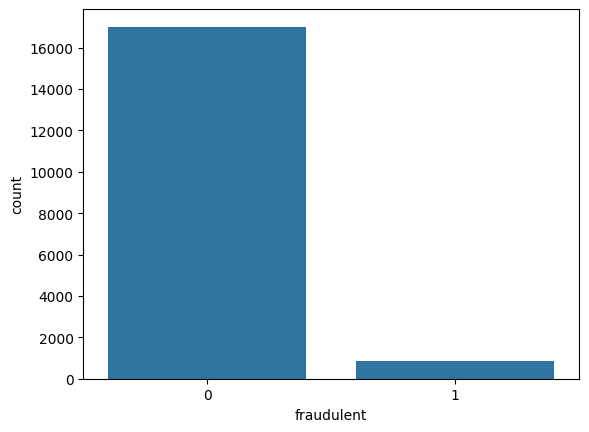

In [31]:
sns.countplot(x='fraudulent',data=df)

plt.show()

In [ ]:
text=df["title"]+" "+df["company_profile"]+" "+df["description"]+" "+df["requirements"]+" "+df["benefits"]

target=df["fraudulent"]

In [32]:
stop_words=set(stopwords.words("english"))

def clean_text(text):

    text=text.lower()

    text=re.sub(r'http\S+'," ",text)

    text=re.sub(r'[^a-zA-Z]'," ",text)

    text=text.split()

    text=[word for word in text if word not in stop_words]

    return " ".join(text)

text=text.apply(clean_text)

In [ ]:
tfidf=TfidfVectorizer(max_features=5000)

X=tfidf.fit_transform(text)

y=target

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(
X,
y,
test_size=0.2,
random_state=42)

In [ ]:
lr=LogisticRegression()

lr.fit(X_train,y_train)

pred1=lr.predict(X_test)

print(accuracy_score(y_test,pred1))

print(classification_report(y_test,pred1))

0.9717561521252797
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      3395
           1       1.00      0.44      0.61       181

    accuracy                           0.97      3576
   macro avg       0.99      0.72      0.80      3576
weighted avg       0.97      0.97      0.97      3576



In [ ]:
nb=MultinomialNB()

nb.fit(X_train,y_train)

pred2=nb.predict(X_test)

print(accuracy_score(y_test,pred2))

print(classification_report(y_test,pred2))

0.9664429530201343
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3395
           1       0.98      0.34      0.51       181

    accuracy                           0.97      3576
   macro avg       0.98      0.67      0.75      3576
weighted avg       0.97      0.97      0.96      3576



In [ ]:
rf=RandomForestClassifier()

rf.fit(X_train,y_train)

pred3=rf.predict(X_test)

print(accuracy_score(y_test,pred3))

print(classification_report(y_test,pred3))

0.9807046979865772
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3395
           1       1.00      0.62      0.76       181

    accuracy                           0.98      3576
   macro avg       0.99      0.81      0.88      3576
weighted avg       0.98      0.98      0.98      3576



In [ ]:
results=pd.DataFrame({

'Model':['Logistic Regression',
         'Naive Bayes',
         'Random Forest'],

'Accuracy':[

accuracy_score(y_test,pred1),

accuracy_score(y_test,pred2),

accuracy_score(y_test,pred3)]

})

results

,Model,Accuracy
0,Logistic Regression,0.971756
1,Naive Bayes,0.966443
2,Random Forest,0.980705


In [ ]:
results.to_csv("/content/drive/MyDrive/Fake_Job_Posting_Project/model_results.csv",index=False)

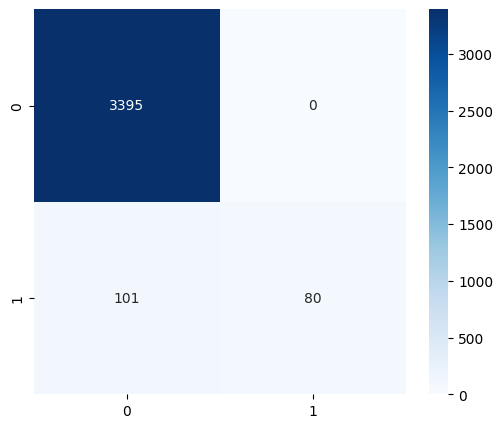

In [ ]:
cm=confusion_matrix(y_test,pred1)

plt.figure(figsize=(6,5))

sns.heatmap(cm,
annot=True,
fmt='d',
cmap='Blues')

plt.savefig("/content/drive/MyDrive/Fake_Job_Posting_Project/confusion_matrix.png")

plt.show()

In [ ]:
joblib.dump(lr,
"/content/drive/MyDrive/Fake_Job_Posting_Project/fake_job_model.pkl")

['/content/drive/MyDrive/Fake_Job_Posting_Project/fake_job_model.pkl']

In [ ]:
joblib.dump(tfidf,
"/content/drive/MyDrive/Fake_Job_Posting_Project/tfidf.pkl")

['/content/drive/MyDrive/Fake_Job_Posting_Project/tfidf.pkl']

In [ ]:
model=joblib.load("/content/drive/MyDrive/Fake_Job_Posting_Project/fake_job_model.pkl")

vectorizer=joblib.load("/content/drive/MyDrive/Fake_Job_Posting_Project/tfidf.pkl")

In [ ]:
sample="""

Software Engineer

Python

Machine Learning

TensorFlow

Remote Job

Excellent Salary

"""

sample=clean_text(sample)

sample=vectorizer.transform([sample])

prediction=model.predict(sample)

if prediction[0]==0:
    print("Legitimate Job Posting")
else:
    print("Fraudulent Job Posting")

Legitimate Job Posting
